# Proyecto: Venteo y Quema de Gas

**Pregunta de investigación:** ¿Qué factores (estado, tipo de tierra, estación, región offshore y período) están **asociados** con una mayor proporción o probabilidad de gas venteado o quemado frente a gas vendido?

> Nota: el objetivo es identificar **asociaciones** en datos observacionales. No se afirma causalidad. (Consultar eso a la profe)

**Fuente:** `OGORBcsv.csv` (producción y disposición de hidrocarburos, Mensual, 2015-01 a 2025-05).

## Parte 1 - Carga de librerias y Dataset

### 1.1 - Librerias

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import optuna

#Ver las librerias TratifiedkFold y GridSearchCV
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV 

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

#Ver si esta bien estas metricas. No le ha visto (hasta el notebook 13)
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, accuracy_score, f1_score)

#Si estan vistas: matriz de confusión y ROC es de las últimas clases, y precision también. F1 es de las primeras clases. Accuracy es de las primeras clases.

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


#Creo que esto hay que sacarlo
# Optuna es opcional: si no está instalado, se usa GridSearchCV con la misma función objetivo.
#try:
    #import optuna
    #optuna.logging.set_verbosity(optuna.logging.WARNING)
    #HAS_OPTUNA = True
#except ImportError:
    #HAS_OPTUNA = False
#print('Optuna disponible:', HAS_OPTUNA)

#Gridsearch se utiliza en el notebook 22, pero podriamos hacerlo con optuna.

/Users/julianquinteros/Documents/Mi-Proyecto/.venv-1/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 - Carga y presentacion del dataset

In [2]:
RUTA = 'OGORBcsv.csv'
df = pd.read_csv(RUTA) 
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (470830, 11)


,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
0,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0
1,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"14,508,756"
2,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"1,207,520"
3,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"487,324"
4,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"114,808"


In [3]:
df.tail()

,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
470825,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),62,Vented Gas Well Gas - Royalty Not Due,0
470826,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),66,Flared Oil Well Gas - Royalty Due,0
470827,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),67,Flared Gas Well Gas - Royalty Due,0
470828,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),68,Vented Oil Well Gas - Royalty Due,0
470829,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),69,Vented Gas Well Gas - Royalty Due,0


### 1.3 - Normalizar nombres de las columnas

In [4]:
# Normalización de nombres de columnas
df.columns = [re.sub(r'\s+', '_', c.strip().lower()) for c in df.columns]
print(df.columns.tolist())

['production_date', 'land_class', 'land_category', 'state', 'county', 'fips_code', 'offshore_region', 'commodity', 'disposition_code', 'disposition_description', 'volume']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 470830 entries, 0 to 470829
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   production_date          470830 non-null  str    
 1   land_class               470830 non-null  str    
 2   land_category            470830 non-null  str    
 3   state                    454200 non-null  str    
 4   county                   454200 non-null  str    
 5   fips_code                454200 non-null  float64
 6   offshore_region          10196 non-null   str    
 7   commodity                470830 non-null  str    
 8   disposition_code         470830 non-null  int64  
 9   disposition_description  470830 non-null  str    
 10  volume                   470830 non-null  str    
dtypes: float64(1), int64(1), str(9)
memory usage: 39.5 MB


Observo que hay un total de 470830 filas y 11 columnas

La mayoria variables categoricas a excepcion de flips code y disposition code. Tambien me doy cuenta que hay un error respecto a los valores de volumen.

Estos se muestran como "str" cuando son valores numericos. Esto se debe a que hay "," en los valores. Es necesario solucionar esto

## Parte 2 - Analisis de datos


### 2.1 - Problema 1: formato numérico de `volume`
Comprobamos el formato real y la conversión antes de aplicarla.

In [6]:
#Me traico 5 valores para comprobar esto de "," en la unidad de volumen
print('Ejemplos con separador de miles:')
print(df.loc[df['volume'].str.contains(','), 'volume'].head(5).tolist())

#Cuenta los valores que esten vacios o solo contienen espacios. Valores como NaN o 0 no se cuentan
print('\nValores vacíos en volume:', (df['volume'].str.strip() == '').sum())

#Cambio el "," del dataset y lo pego en la misma columna
df['volume'] = pd.to_numeric(df['volume'].str.replace(',', '', regex=False), errors='coerce')

#Veo valores negativos
print('Valores negativos:', (df['volume'] < 0).sum())

print('Verificación del tipo de dato:', df['volume'].dtype)


Ejemplos con separador de miles:
['14,508,756', '1,207,520', '487,324', '114,808', '1,160']

Valores vacíos en volume: 0
Valores negativos: 13036
Verificación del tipo de dato: int64


In [7]:
#Verifico otra vez.
df.head()

,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume
0,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0
1,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756
2,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520
3,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324
4,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808


### 2.2 - Unidades físicas distintas (gas en Mcf vs. petróleo en bbl)
Verificamos que `commodity` separe ambas unidades. **No se suman volúmenes de gas y petróleo.**

In [8]:
# Se usa la columna 'volume' ya convertida a numérico
print(df.groupby('commodity')['volume'].agg(['count', 'sum']))
#.agg es para aplicar varias funciones de agregación a la vez. En este caso, se cuentan los registros y se suman los volúmenes por cada tipo de commodity.
#Lo que quiere decir es que, por ejemplo, para Gas hay 1.000.000 de registros y un volumen total de 500.000 Mcf, mientras que para Petróleo hay 500.000 registros y un volumen total de 300.000 barriles.
#Creo que .agg no esta en ningun notebook. Es de Pandas.
print('\nLa suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).')

            count          sum
commodity                     
Gas (Mcf)  235415  51194121625
Oil (bbl)  235415  11224187465

La suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).


### 2.3 - Problema 3: formato de `production_date`
El formato es `MM/DD/YYYY` con día siempre 01. Verificamos antes de convertir.

In [9]:

print('Formatos únicos (patrón):', df['production_date'].str.replace(r'\d', '9', regex=True).unique())

#Cantidad de valores distintos
print('Día del mes distinto de 01:', (~df['production_date'].str.startswith('01/')).sum())

df['production_date'] = pd.to_datetime(df['production_date'], format='%m/%d/%Y', errors='coerce')

#Valores nulos en fechas
print('Fechas no interpretables:', df['production_date'].isna().sum())

#Rango de fechas
print('Rango:', df['production_date'].min().date(), '->', df['production_date'].max().date())

#Veo la cantidad de meses y me matchea con lo visto mas arriba en filas duplicadas y sin info
print('Meses distintos:', df['production_date'].nunique())


Formatos únicos (patrón): <StringArray>
['99/99/9999']
Length: 1, dtype: str
Día del mes distinto de 01: 429446
Fechas no interpretables: 0
Rango: 2015-01-01 -> 2025-05-01
Meses distintos: 125


### 2.4 - Problema 4: códigos de disposición
Construimos la tabla de correspondencia **antes** de sumar nada.

Clasificación adoptada (documentada en el informe):
- **Venta comercial (gas):** 01, 04, 05, 06, 09, 15, 43.
- **Venteo:** 61, 62, 63, 68, 69 (*Vented*).
- **Quema / flaring:** 21, 22, 33, 66, 67 (*Flared*).
- **Otros destinos internos o contables** (11 transferido a instalación, 20 uso en lugar, 14 inyección, 42 ajustes, 25 buy-back, etc.): **no son venta ni pérdida**, se excluyen.

In [10]:
relacion = (
    df[['disposition_code', 'disposition_description']]
    .drop_duplicates()
    .sort_values(['disposition_code', 'disposition_description'])
    .reset_index(drop=True)
)

relacion

,disposition_code,disposition_description
0,1,Sales-Royalty Due-MEASURED
1,3,Load Oil
2,4,Sales-Royalty Due-Not Measured
3,5,"Sales-Royalty Not Due, Recovered Injection-MEA..."
4,6,Sales-Non-Hydrocarbon Gas
5,7,Condensate Sales-Royalty Due-MEASURED
6,8,Spilled and/or Lost-Avoidable-Royalty Due
7,9,Sales-Royalty Not Due-MEASURED
8,10,Produced into Inventory Prior to Sales
9,11,Transferred to Facility


In [11]:
#Este codigo es para filtrar el dataframe y quedarme solo con los registros de Gas (Mcf).
#Luego, se crea una nueva columna 'tipo_disposicion' que clasifica cada registro en 'Sales', 'Vented',
#'Flared' o 'Revisar' según las palabras clave encontradas en la descripción de disposición.
#Finalmente, se genera una tabla resumen que agrupa los registros por tipo de disposición,
#código y descripción, mostrando la cantidad de registros para cada combinación.
df_gas = df.loc[df['commodity'].eq('Gas (Mcf)')].copy()

descripcion = (
    df_gas['disposition_description']
    .fillna('')
    .astype('string')
    .str.strip()
)

# Recomendación: usar paréntesis con ?: para usar grupos no capturantes, lo que mejora 
# el rendimiento de las expresiones regulares. Esto es útil cuando solo se necesita 
# verificar la presencia de palabras clave sin necesidad de capturarlas para su 
# posterior uso.
coincidencias = pd.DataFrame({
    'Sales': descripcion.str.contains(
        r'\b(?:sale|sales|sold)\b', case=False, na=False
    ),
    'Vented': descripcion.str.contains(
        r'\b(?:vent|vented|venting)\b', case=False, na=False
    ),
    'Flared': descripcion.str.contains(
        r'\b(?:flare|flared|flaring)\b', case=False, na=False
    )
}, index=df_gas.index)

df_gas['tipo_disposicion'] = np.select(
    [
        coincidencias['Sales'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Vented'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Flared'] & coincidencias.sum(axis=1).eq(1)
    ],
    ['Sales', 'Vented', 'Flared'],
    default='Revisar'
)

tabla_tipos = (
    df_gas.groupby(
        ['tipo_disposicion', 'disposition_code', 'disposition_description'],
        dropna=False
    )
    .size()
    .reset_index(name='registros')
    .sort_values(['tipo_disposicion', 'disposition_code'])
    .reset_index(drop=True)
)

tabla_tipos

,tipo_disposicion,disposition_code,disposition_description,registros
0,Flared,21,Flared Oil Well Gas - Royalty Not Due,8986
1,Flared,22,Flared Gas Well Gas - Royalty Not Due,4567
2,Flared,33,Flared Gas - Royalty Due,2884
3,Flared,66,Flared Oil Well Gas - Royalty Due,2445
4,Flared,67,Flared Gas Well Gas - Royalty Due,572
5,Revisar,3,Load Oil,90
6,Revisar,8,Spilled and/or Lost-Avoidable-Royalty Due,1206
7,Revisar,11,Transferred to Facility,17465
8,Revisar,12,Transferred to Facility-Returned to L/A,1496
9,Revisar,13,Transferred from Facility,5264


In [12]:
#Creo las columnas
VENTA = [1, 4, 5, 6, 7, 9, 15, 43]
VENTEO = [61, 62, 63, 68, 69]
QUEMA = [21, 22, 33, 66, 67]

#Creo una copia con el df original y creo otro llamado 'gas'. Este es el que vamos a trabajar
gas = df[df['commodity'] == 'Gas (Mcf)'].copy()

#Defino la funcion
def categorizar(c):
    if c in VENTA:  return 'venta'
    if c in VENTEO: return 'venteo'
    if c in QUEMA:  return 'quema'
    return 'otro'

#Agrego una columna "categoria" para diferenciar los tipos de disposicion
gas['categoria'] = gas['disposition_code'].map(categorizar)

#Creo la tabla agrupando los valores que necesitamos
tabla_codigos = (gas.groupby(['disposition_code', 'disposition_description', 'categoria'])
                    .agg(registros=('volume', 'size'), volumen_mcf=('volume', 'sum'))
                    .reset_index())

#Ordeno la tabla
orden = ['venta', 'venteo', 'quema', 'otro']

tabla_codigos['categoria'] = pd.Categorical(
    tabla_codigos['categoria'],
    categories=orden,
    ordered=True
)

tabla_codigos = tabla_codigos.sort_values(
    ['categoria', 'disposition_code']
).reset_index(drop=True)


tabla_codigos

,disposition_code,disposition_description,categoria,registros,volumen_mcf
0,1,Sales-Royalty Due-MEASURED,venta,31512,12783398822
1,4,Sales-Royalty Due-Not Measured,venta,3477,31071152
2,5,"Sales-Royalty Not Due, Recovered Injection-MEA...",venta,377,119447925
3,6,Sales-Non-Hydrocarbon Gas,venta,847,2951838075
4,7,Condensate Sales-Royalty Due-MEASURED,venta,386,0
5,9,Sales-Royalty Not Due-MEASURED,venta,1548,1676110371
6,15,Sales-Buy-Back-Measured-Royalty Not Due,venta,1831,1334022108
7,43,Sales-Royalty Not Due-FMP Not Assigned,venta,39,1254
8,61,Vented Oil Well Gas - Royalty Not Due,venteo,4400,23170382
9,62,Vented Gas Well Gas - Royalty Not Due,venteo,3935,14168710


### 2.5 - Resumen de todas las correcciones

In [13]:

informe = pd.DataFrame([
    ['volume', 'Texto con comas de miles', 'Conversión numérica tras quitar comas',
     f"{len(df):,} registros", f"No convertibles: {df['volume'].isna().sum()}"],

    ['Unidades', 'Gas (Mcf) y Petróleo (bbl) mezclados', 'Filtro solo Gas (Mcf)',
     f"{(df['commodity']!='Gas (Mcf)').sum():,} petróleo excluido", 'Sin suma cruzada'],

    ['production_date', 'MM/DD/YYYY, día 01', 'pd.to_datetime con formato explícito',
     f"{df['production_date'].isna().sum()} no válidas", 'Rango 2015-01 a 2025-05'],

    ['disposition_code', '33 códigos', 'Tabla de correspondencia documentada',
     f"{gas['categoria'].value_counts().get('otro', 0):,} de gas excluidos (otros destinos)",
     'Solo venta/venteo/quema en el análisis'],

], columns=['Problema', 'Diagnóstico', 'Corrección', 'Registros afectados', 'Validación'])

informe

,Problema,Diagnóstico,Corrección,Registros afectados,Validación
0,volume,Texto con comas de miles,Conversión numérica tras quitar comas,"470,830 registros",No convertibles: 0
1,Unidades,Gas (Mcf) y Petróleo (bbl) mezclados,Filtro solo Gas (Mcf),"235,415 petróleo excluido",Sin suma cruzada
2,production_date,"MM/DD/YYYY, día 01",pd.to_datetime con formato explícito,0 no válidas,Rango 2015-01 a 2025-05
3,disposition_code,33 códigos,Tabla de correspondencia documentada,"166,451 de gas excluidos (otros destinos)",Solo venta/venteo/quema en el análisis


## Parte 3 - Limpieza y preparacion del dataset

- Se trabaja solo con gas.
- Se usan los registros venta, venteo y quema. Los demás destinos se excluyen.
- Los valores negativos de `volume` se **truncan a cero** solo para el cálculo de proporciones de disposición (representan reversiones y no volumen vendido/perdido). Se documenta.
- Se revisan duplicados y valores faltantes en las variables clave.

### 3.1 - Limpio el dataset
Excluyos los datos del dataset que no vamos a usar. Para ello creamos otro dataset llamado gas_limpio.

Basicamente saco las filas que no vamos a usar

In [14]:
#Creo una nueva copia con el dataframe que vamos a trabajar
gas_limpio = gas[gas['categoria'].isin(['venta', 'venteo', 'quema'])].copy()
#Una alternativa a esto es trabajar con el mismo df: gas pero haciendo drop de las filas con categoria: otros
#Con isin me devuelve True si la categoria es correcta y lo copia

#Creo una nueva columna "Perdida" para considerar los valores de venteo y quema
gas_limpio['perdida'] = gas_limpio['categoria'].isin(['venteo', 'quema']).astype(int)

#Reseteo el indice
gas_limpio.reset_index(drop=True, inplace=True)
gas_limpio.head()


,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida
0,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0
1,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0
2,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0
3,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0
4,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0


### 3.2 - Valores duplicados 

In [15]:
#Comparo y verifico si hay algun valor duplicado
print('Registros de gas totales:', len(gas)) 
print('Registros en el análisis:', len(gas_limpio))
print('Duplicados exactos en el df limpio:', gas_limpio.duplicated().sum())
#No hay valores duplicados

Registros de gas totales: 235415
Registros en el análisis: 68964
Duplicados exactos en el df limpio: 0


In [16]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    65351 non-null  str           
 4   county                   65351 non-null  str           
 5   fips_code                65351 non-null  float64       
 6   offshore_region          2077 non-null   str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

### 3.3 - Valores sin aporte de informacion

Aca lo que busco ver es la cantidad de informacion que tiene cada columna. Si en una columna solo hay un valor o dos (dependiendo el caso) es muy probable que esa informacion que contiene no es mucha o buena

En este caso vemos que solo commodity posee un valor pero es logico ya que filtramos por Gas. Asi que esta bien

Por otro lado el resto de variables categoricas que poseen 2 o 3 valores tambien son correctas.

In [17]:
Var_sin_info = gas_limpio.nunique().sort_values()
print("\nValores distintos por columna:")
print(Var_sin_info.head(13))


Valores distintos por columna:
commodity                      1
land_category                  2
perdida                        2
land_class                     3
offshore_region                3
categoria                      3
disposition_code              18
disposition_description       18
state                         26
production_date              125
county                       281
fips_code                    315
volume                     25707
dtype: int64


### 3.4 - Variables derivadas y correciones

Primero voy a hacer un cruce entre los datos de state. Aquellas observaciones cuyos valores en state estan vacios se le va agregar offshore y aquellos valores vacios en la columna de offshore_region se le agregara onshore

Esto es porque se interpreta que si el dato falta en state es porque corresponde a un yacimiento de offshore y viceversa con la columna offshore_region

#### VERIFICAR LO DE STATE Y OFFSHORE -> Verificar qué? No habíamos dicho que era así? Creo que está bien



Ademas creo variables derivadas respecto al tiempo. Estas columnas agruparan año, mes y estacion

Se utilizara para el modelo predictivo

Por otro lado nos damos cuenta que hay volumenes negativos. Esto es por muchas razones pero a la hora de los calculos matematicos nos perjudicaria asi que hacemos que los valores que negativos pasen a ser 0 y los valores positivos y nulos quedaran igual

'Aclaracion:'  Los valores NaN o faltantes no seran reemplazados en ninguno de los casos descriptos. En otro apartado se realizara el analisis sobre estos

Veamos qué porcentaje de valores faltantes hay en cada columna:

In [18]:
#Análisis de valores faltantes en las columnas de interés
faltantes = pd.DataFrame({
    "Cantidad":gas_limpio.isna().sum(),
    "Porcentaje":(gas_limpio.isna().sum() / len(gas_limpio) * 100).round(2)
})

faltantes = faltantes[faltantes["Cantidad"] > 0].sort_values(by="Cantidad", ascending=False)
#Esta línea es para filtrar solo las columnas que tienen valores faltantes y ordenarlas de mayor a menor.
faltantes


,Cantidad,Porcentaje
offshore_region,66887,96.9900
state,3613,5.2400
county,3613,5.2400
fips_code,3613,5.2400


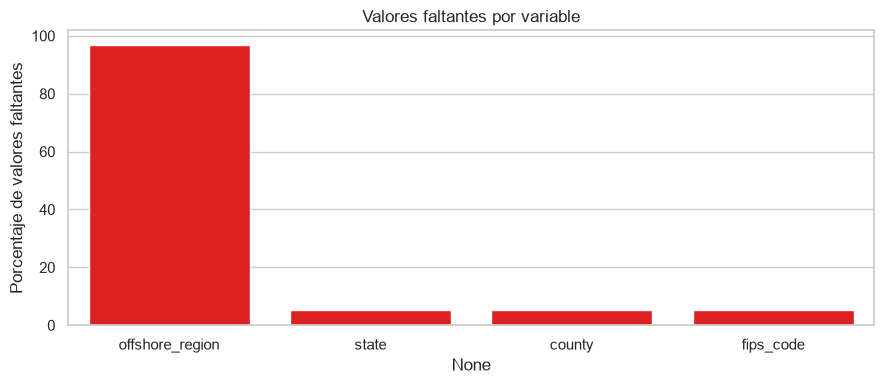

In [19]:
# Gráfico
plt.figure(figsize=(9, 4))
sns.barplot(x=faltantes.index, y=faltantes["Porcentaje"], color='red')
plt.ylabel("Porcentaje de valores faltantes")
plt.title("Valores faltantes por variable")
plt.tight_layout()
plt.show()

In [20]:
# Hacemos el cruce entre 'Onshore' y 'offshore_region' con una máscara booleana.
# La máscara indica qué filas cumplen con una condición específica: que la columna
# 'land_category'sea igual a 'Onshore' y que la columna 'offshore_region' sea nula.
mask = (
    gas_limpio['land_category'].eq('Onshore')
    & gas_limpio['offshore_region'].isna()
)
gas_limpio.loc[mask, 'offshore_region'] = 'Onshore'
# Llamamos a gas_limpio para ver que se hayan aplicado los cambios
# gas_limpio


Ahora, nos enfocamos en las columnas 'state', 'county' y 'fips_code'

In [21]:
# Identificamos si estas 3 columnas están vacías en todos los land_category == 'offshore'
columnas = ['state', 'county', 'fips_code']
offshore = gas_limpio.loc[gas_limpio['land_category'].astype('string').str.contains('Offshore', case=False, na=False)]
# Contamos los isna en cada columna.
print(offshore[columnas].isna().sum())
#Contamos las filas donde las tres columnas son NaN.
print(offshore[columnas].isna().all(axis=1).sum())
#Contamos las filas donde las columnas son espacios vacíos sin NaN.
print((offshore[columnas] == ' ').sum())

state        2077
county       2077
fips_code    2077
dtype: int64
2077
state        0
county       0
fips_code    0
dtype: int64


In [22]:
#En todas las filas donde tenemos land_category == 'Offshore', las columnas state, 
# county y fips_code están vacías, colocamos 'Offshore' en las tres columnas. 
# Esto es para que no queden vacías y se pueda trabajar con ellas en análisis posteriores.
# Primero, hacemos que fips_code acepte string y no float64
gas_limpio['fips_code'] = gas_limpio['fips_code'].astype('string')
gas_limpio.loc[gas_limpio['land_category'].astype('string').str.contains('Offshore', case=False, na=False), columnas] = 'Offshore'
# A las filas que tienen Onshore en land category y NaN en las otras 3 columnas, les ponemos
# "Sin información" para que no queden vacías y se pueda trabajar con ellas en análisis 
# posteriores.
gas_limpio.loc[gas_limpio['land_category'].astype('string').str.contains('Onshore', case=False, na=False) & gas_limpio[columnas].isna().all(axis=1), columnas] = 'Sin información'
# Llamamos a gas_limpio para ver que se hayan aplicado los cambios
gas_limpio

,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida
0,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0
1,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0
2,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0
3,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0
4,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
68959,2025-05-01,Native American,Onshore,Sin información,Sin información,Sin información,Onshore,Gas (Mcf),62,Vented Gas Well Gas - Royalty Not Due,1660,venteo,1
68960,2025-05-01,Native American,Onshore,Sin información,Sin información,Sin información,Onshore,Gas (Mcf),66,Flared Oil Well Gas - Royalty Due,60333,quema,1
68961,2025-05-01,Native American,Onshore,Sin información,Sin información,Sin información,Onshore,Gas (Mcf),67,Flared Gas Well Gas - Royalty Due,649,quema,1
68962,2025-05-01,Native American,Onshore,Sin información,Sin información,Sin información,Onshore,Gas (Mcf),68,Vented Oil Well Gas - Royalty Due,3114,venteo,1


In [23]:

#Creo la columnas temporales por si necesito usarla mas adelante
gas_limpio['year'] = gas_limpio['production_date'].dt.year
gas_limpio['month'] = gas_limpio['production_date'].dt.month
gas_limpio['season'] = gas_limpio['month'].map({
    12: 'Invierno', 1: 'Invierno', 2: 'Invierno',
    3: 'Primavera', 4: 'Primavera', 5: 'Primavera',
    6: 'Verano', 7: 'Verano', 8: 'Verano',
    9: 'Otoño', 10: 'Otoño', 11: 'Otoño'
})

#Hay volumenes negativos. Con esto quiero que los negativos pasen a ser 0, los positivos y nulos queden igual
#Esto es para que no me afecte en los calculos
gas_limpio['vol_pos'] = gas_limpio['volume'].clip(lower=0)

gas_limpio.head()



,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida,year,month,season,vol_pos
0,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0,2015,1,Invierno,0
1,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0,2015,1,Invierno,14508756
2,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0,2015,1,Invierno,1207520
3,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0,2015,1,Invierno,487324
4,2015-01-01,Federal,Offshore,Offshore,Offshore,Offshore,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0,2015,1,Invierno,114808


### 3.5 - Valores faltantes

In [24]:
print('\nValores faltantes en variables clave:')
print(gas_limpio.isna().sum())



Valores faltantes en variables clave:
production_date            0
land_class                 0
land_category              0
state                      0
county                     0
fips_code                  0
offshore_region            0
commodity                  0
disposition_code           0
disposition_description    0
volume                     0
categoria                  0
perdida                    0
year                       0
month                      0
season                     0
vol_pos                    0
dtype: int64


In [25]:
print('\n Proporcion de valores faltantes:')
print(gas_limpio.isna().mean()*100)


 Proporcion de valores faltantes:
production_date           0.0000
land_class                0.0000
land_category             0.0000
state                     0.0000
county                    0.0000
fips_code                 0.0000
offshore_region           0.0000
commodity                 0.0000
disposition_code          0.0000
disposition_description   0.0000
volume                    0.0000
categoria                 0.0000
perdida                   0.0000
year                      0.0000
month                     0.0000
season                    0.0000
vol_pos                   0.0000
dtype: float64


### 3.6 - Outliers

In [26]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    68964 non-null  str           
 4   county                   68964 non-null  str           
 5   fips_code                68964 non-null  string        
 6   offshore_region          68964 non-null  str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

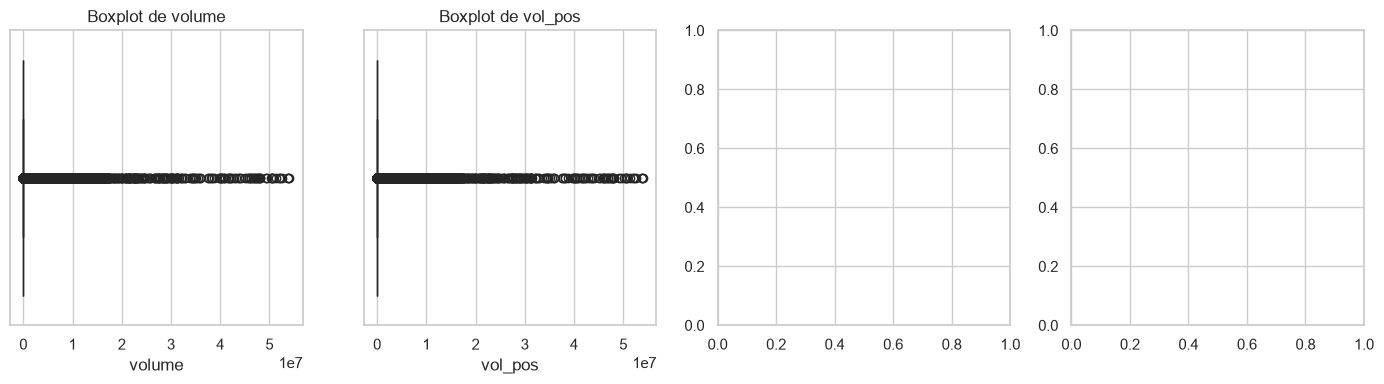

In [27]:
outliers_variables = ["volume", "vol_pos"]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for eje, variable in zip(axes, outliers_variables):
    sns.boxplot(x=gas_limpio[variable], ax=eje, color='green')
    eje.set_title(f'Boxplot de {variable}')
    eje.set_ylabel("")
plt.tight_layout()
plt.show()

Vol_pos es difícil de leer porque hay una distribución muy sesgada: valores muy pequeños y unos pocos muy grandes que hacen que se "estire" todo.

Como no tenemos valores negativos en vol_pos, lo vamos a transformar con log1p, aplicando log(1 + valor).

*Alam decime que opinas de esto <---------

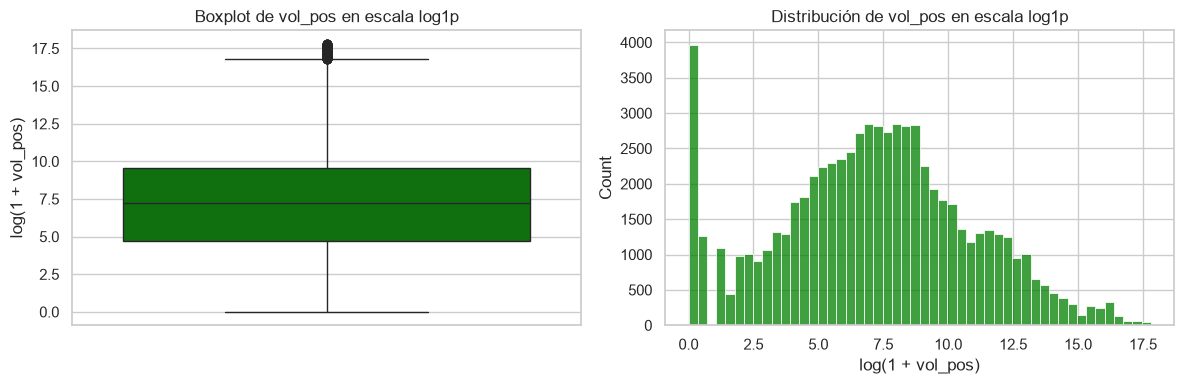

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
vol_pos_log = np.log1p(gas_limpio['vol_pos'])

sns.boxplot(y=vol_pos_log, ax=axes[0], color='green')
axes[0].set_title('Boxplot de vol_pos en escala log1p')
axes[0].set_ylabel('log(1 + vol_pos)')

sns.histplot(vol_pos_log, bins=50, ax=axes[1], color='green')
axes[1].set_title('Distribución de vol_pos en escala log1p')
axes[1].set_xlabel('log(1 + vol_pos)')

plt.tight_layout()
plt.show()

Ahora vamos a graficar 'volume' solo, sin 'vol_pos', para visualizar bien sus datos.

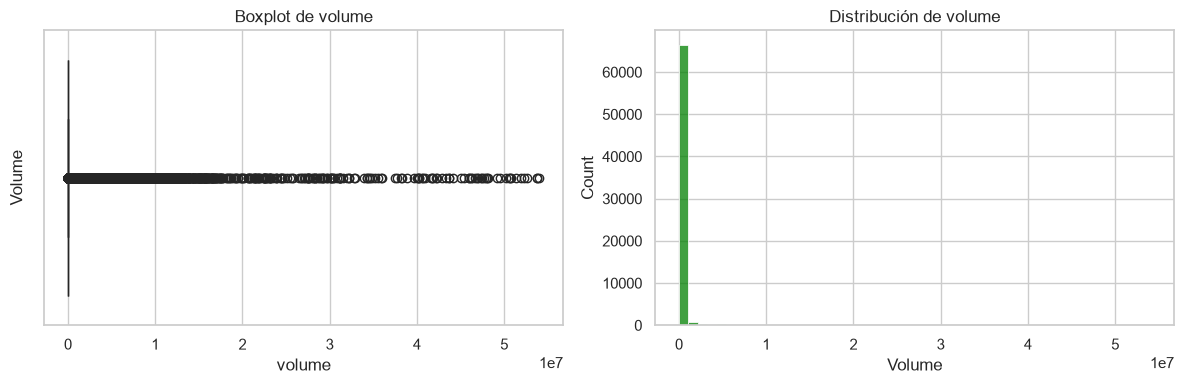

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=gas_limpio['volume'], ax=axes[0], color='green')
axes[0].set_title('Boxplot de volume')
axes[0].set_ylabel('Volume')

sns.histplot(gas_limpio['volume'], bins=50, ax=axes[1], color='green')
axes[1].set_title('Distribución de volume')
axes[1].set_xlabel('Volume')

plt.tight_layout()
plt.show()

Que el boxplot de 'volume' quede chato significa que no hay outliers, y también se ve en la distribución del histograma.

En el histograma de 'volume' vemos una concentración alta cerca de cero, y una cola larga hacia la derecha indicaría que hay muchos volúmenes pequeños y unos pocos muy grandes.

El histograma de 'vol_pos' me muestra una distribución después de llevar los negativos a cero. Los valores positivos se mantienen.

*Alguna interpretación más? Agregar más cosas además de volume y vol_pos?  <---

*Ahora, junto los 4 gráficos. Decidir si mostramos por separado o si mostramos todo junto. <---

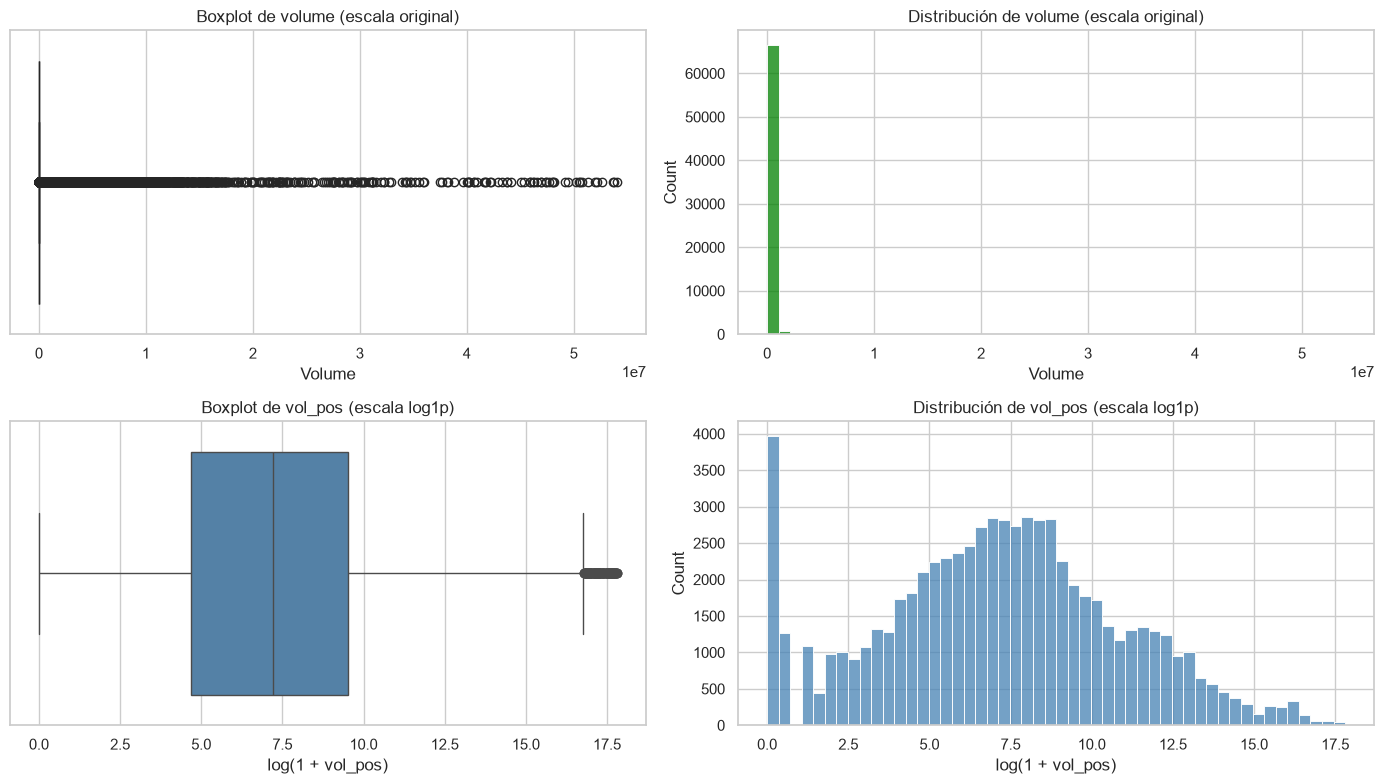

In [35]:
vol_pos_log = np.log1p(gas_limpio['vol_pos'])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.boxplot(x=gas_limpio['volume'], ax=axes[0, 0], color='green')
axes[0, 0].set_title('Boxplot de volume (escala original)')
axes[0, 0].set_xlabel('Volume')

sns.histplot(
    data=gas_limpio, x='volume', bins=50,
    ax=axes[0, 1], color='green'
)
axes[0, 1].set_title('Distribución de volume (escala original)')
axes[0, 1].set_xlabel('Volume')

sns.boxplot(x=vol_pos_log, ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Boxplot de vol_pos (escala log1p)')
axes[1, 0].set_xlabel('log(1 + vol_pos)')

sns.histplot(vol_pos_log, bins=50, ax=axes[1, 1], color='steelblue')
axes[1, 1].set_title('Distribución de vol_pos (escala log1p)')
axes[1, 1].set_xlabel('log(1 + vol_pos)')

plt.tight_layout()
plt.show()

Como en uno uso log1p y en otro no, los ejes son distintos y las alturas de los boxplots no se comparan de manera directa.

*Alguna otra manera de visualizar 'volume'? Está un poco incómodo <---

### IQR y Z-Score para comparar, aunque ya decidimos usar IQR

In [38]:
# No modificar el DF, solo visualizar.

vol = gas_limpio['vol_pos'].dropna()

# IQR
Q1=vol.quantile(0.25)
Q3=vol.quantile(0.75)
IQR = Q3 - Q1

lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR

outlier_iqr = (vol < lb) | (vol > ub)

# Z-Score: marca valores a más de 3 desviaciones estándar; no podemos asegurar que los valores sean normales, pero es una aproximación.

z_score = (vol - vol.mean()) / vol.std(ddof=0)
outlier_z = z_score.abs() > 3

#Comparamos.

print('IQR - límites:', lb, 'a', ub)
print('IQR - posibles outliers:', outlier_iqr.sum())
print('Z-Score - posibles outliers:', outlier_z.sum())
print('Detectados por ambos métodos:', (outlier_iqr & outlier_z).sum())
print('Solo por IQR:', (outlier_iqr & ~outlier_z).sum())
print('Solo por Z-Score:', (~outlier_iqr & outlier_z).sum())

IQR - límites: -20297.625 a 34117.375
IQR - posibles outliers: 12805
Z-Score - posibles outliers: 883
Detectados por ambos métodos: 883
Solo por IQR: 11922
Solo por Z-Score: 0


#### Interpretación

- IQR marca 12805 valores por encima del UP de 34117.375 como posibles outliers. El LB no importa porque no tenemos valores negativos en vol_pos.
- Z-Score marca 883 valores a más de 3 desviaciones estándar de la media, que también están detectados por IQR.
- El IQR marca 11922 valores más que Z-Score.

El IQR utiliza un criterio más amplio, y probablemente esto se deba a que tenemos mucho sesgo en 'vol_pos', muchos valores pequeños y algunos muy grandes.

El Z-Score depende de la media y la desviación estándar, afectadas por estos valores grandes de la cola.

Un outlier no es necesariamente un error, por lo que no deberíamos de eliminar estos registros automáticamente, ya que podrían ser volúmenes reales y quitarlos afectaría a nuestro análisis del venteo y la quema de gas. Hay que investigar más, y decidir si conservar los datos en caso de que el contexto lo amerite.

In [40]:
# Copiamos solo las líneas que IQR marcó como posibles outliers.
casos_iqr = gas_limpio.loc[outlier_iqr].copy()

print('Filas marcadas:', len(casos_iqr))
print('Porcentaje del total:', round(len(casos_iqr) / len(gas_limpio) * 100, 2), '%')

# 20 valores más altos junto con su contexto (disposition_code y disposition_description) para ver si son realmente outliers o si hay una explicación.
columnas2 = [
    'production_date',
    'land_category',
    'state',
    'county',
    'offshore_region',
    'categoria',
    'disposition_code',
    'disposition_description',
    'volume',
    'vol_pos'
]

display(casos_iqr.sort_values('vol_pos', ascending=False)[columnas2].head(20))

Filas marcadas: 12805
Porcentaje del total: 18.57 %


,production_date,land_category,state,county,offshore_region,categoria,disposition_code,disposition_description,volume,vol_pos
63578,2024-08-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,54038988,54038988
63005,2024-07-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,53753616,53753616
64701,2024-10-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,53713826,53713826
65810,2024-12-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,52618926,52618926
62449,2024-06-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,52217337,52217337
64146,2024-09-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,51945576,51945576
67474,2025-03-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,51334340,51334340
60803,2024-03-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,50737696,50737696
65256,2024-11-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,50609359,50609359
66361,2025-01-01,Onshore,NM,Eddy,Onshore,venta,1,Sales-Royalty Due-MEASURED,50539821,50539821


Veamos la distribución entre ventas, venteo y quema:

In [41]:
resumen_iqr = (casos_iqr.groupby('categoria').agg(
    registros=('vol_pos', 'size'),
    volumen_total=('vol_pos', 'sum'),
    mediana=('vol_pos', 'median'),
    maximo=('vol_pos', 'max')
).sort_values('registros',ascending=False))

display(resumen_iqr)

,registros,volumen_total,mediana,maximo
categoria,,,,
venta,10594,18760454402,"240,131.0000",54038988
quema,1948,451205724,"111,303.5000",4366151
venteo,263,30831408,"97,512.0000",815478


Podemos interpretar:

- De las 12805 filas marcadas, la mayoría son de venta: 10594 (más del 80%). Hay 1948 de quema y 263 de venteo.
- El máximo es mucho mayor para venta que para quema o venteo, por eso la cola tan alta de los gráficos y del IQR.
- Solo estamos viendo los valores mayores a 34117.375 del UB del IQR en vol_pos, no tenemos prueba de que hayan errores, pueden ser registros válidos de gran volumen.

*Teóricamente estos datos oficiales de USA deberían de estar bien, pero habría que seguir analizando <---

*Habría que inspeccionar los registros más altos y sus fechas, ubicaciones y descripciones <---

In [ ]:
# Vamos a utilizar rango intercuartilico (IQR) para detectar y eliminar valores atípicos en la columna 'vol_pos'.
# Calculamos el primer cuartil (Q1) y el tercer cuartil (Q3) de la columna 'vol_pos'.

#Q1 = gas_limpio['vol_pos'].quantile(0.25)
#Q3 = gas_limpio['vol_pos'].quantile(0.75)
#IQR = Q3 - Q1

# Definimos los límites para identificar valores atípicos
#lower_bound = Q1 - 1.5 * IQR
#upper_bound = Q3 + 1.5 * IQR

# Filtramos los datos para eliminar valores atípicos
#gas_limpio = gas_limpio[(gas_limpio['vol_pos'] >= lower_bound) & (gas_limpio['vol_pos'] <= upper_bound)]


# Ahora, que me muestre la cantidad de registros después de eliminar los valores atípicos
#for col in gas_limpio.select_dtypes(include=np.number).columns:
#    print(f'{col:20s} outliers: {contar_outliers(gas_limpio[col])}')

disposition_code     outliers: 0
volume               outliers: 2805
perdida              outliers: 0
year                 outliers: 0
month                outliers: 0
vol_pos              outliers: 2805


## 4. Análisis descriptivo: venta, venteo y quema

Calculamos volúmenes y proporciones con **denominador explícito**: `venta + venteo + quema`.

$$\text{Proporción de pérdida} = \frac{V_{venteo}+V_{quema}}{V_{venta}+V_{venteo}+V_{quema}}$$

In [ ]:
def resumen(grupo):
    t = (d.groupby(grupo)
           .apply(lambda x: pd.Series({
               'vol_venta': x.loc[x.categoria=='venta','vol_pos'].sum(),
               'vol_venteo': x.loc[x.categoria=='venteo','vol_pos'].sum(),
               'vol_quema': x.loc[x.categoria=='quema','vol_pos'].sum(),
               'n_registros': len(x)}), include_groups=False)
           .reset_index())
    t['vol_total'] = t[['vol_venta','vol_venteo','vol_quema']].sum(axis=1)
    t['vol_perdida'] = t['vol_venteo'] + t['vol_quema']
    t['prop_perdida_%'] = np.where(t['vol_total']>0, 100*t['vol_perdida']/t['vol_total'], np.nan)
    return t.sort_values('prop_perdida_%', ascending=False)

total = resumen(['land_class'])
total

In [ ]:
print('Proporción global de pérdida (%):',
      round(100*d.loc[d.perdida==1,'vol_pos'].sum()/d['vol_pos'].sum(), 2))
por_estado = resumen(['state_f'])
# Grupos con poco volumen no permiten conclusiones fiables: se marcan
por_estado['tamano_suficiente'] = por_estado['vol_total'] >= 1e8
print('Estados con volumen < 100 millones Mcf (no concluyentes):', (~por_estado.tamano_suficiente).sum())
por_estado.head(15)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
t = por_estado.sort_values('vol_total', ascending=False).head(12)
ax.bar(t['state_f'], t['vol_perdida']/1e9, color='#C44E52', label='Venteo + quema')
ax.bar(t['state_f'], t['vol_venta']/1e9, bottom=t['vol_perdida']/1e9, color='#55A868', label='Venta')
ax.set_ylabel('Volumen (miles de millones de Mcf)')
ax.set_title('Volumen de gas: venteo/quema vs. venta, por estado (top 12 por volumen total)')
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
s = por_estado[por_estado.vol_total > 1e8].sort_values('prop_perdida_%')
ax.barh(s['state_f'], s['prop_perdida_%'], color='#4C72B0')
ax.set_xlabel('Proporción de pérdida (%)')
ax.set_title('Proporción de gas venteado o quemado por estado (volumen total > 100 millones Mcf)')
plt.tight_layout(); plt.show()

### 4.1 Tipo de tierra y región offshore

In [ ]:
tierra = resumen(['land_class'])
offshore = resumen(['region_offshore'])
display(tierra)
display(offshore)

### 4.2 Estacionalidad y evolución temporal

In [ ]:
mensual = (d.groupby('production_date')
             .apply(lambda x: pd.Series({
                 'vol_total': x['vol_pos'].sum(),
                 'vol_perdida': x.loc[x.perdida==1,'vol_pos'].sum()}), include_groups=False)
             .reset_index())
mensual['prop_perdida_%'] = 100*mensual['vol_perdida']/mensual['vol_total']

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(mensual['production_date'], mensual['prop_perdida_%'], color='#C44E52')
ax.set_title('Proporción mensual de gas venteado o quemado (%)')
ax.set_ylabel('%'); plt.tight_layout(); plt.show()

est = resumen(['estacion']).set_index('estacion').loc[['Verano','Otoño','Invierno','Primavera']]
est[['prop_perdida_%']]

## 5. Dataset a nivel grupo y test de diferencias

Agregamos por **estado × tipo de tierra × mes** para estudiar la proporción de pérdida como variable continua en (0,1). Luego comparamos grupos con pruebas no paramétricas, dado que las proporciones son asimétricas.

In [ ]:
grupo = (d.groupby(['state_f','land_class','production_date'])
           .apply(lambda x: pd.Series({
               'vol_total': x['vol_pos'].sum(),
               'vol_perdida': x.loc[x.perdida==1,'vol_pos'].sum(),
               'estacion': x['estacion'].iloc[0],
               'anio': x['anio'].iloc[0]}), include_groups=False)
           .reset_index())
grupo = grupo[grupo['vol_total'] > 0].copy()
grupo['prop_perdida'] = grupo['vol_perdida'] / grupo['vol_total']
print('Grupos:', grupo.shape[0])
grupo['prop_perdida'].describe()

In [ ]:
# Diferencias por tipo de tierra (Kruskal-Wallis, no paramétrico)
grupos_tierra = [g['prop_perdida'].values for _, g in grupo.groupby('land_class')]
H, p = stats.kruskal(*grupos_tierra)
print(f'Kruskal-Wallis por tipo de tierra: H={H:.2f}, p={p:.2e}')

grupos_est = [g['prop_perdida'].values for _, g in grupo.groupby('estacion')]
H2, p2 = stats.kruskal(*grupos_est)
print(f'Kruskal-Wallis por estación: H={H2:.2f}, p={p2:.2e}')
print('\nNota: con muchos grupos, cualquier diferencia pequeña resulta significativa; se prioriza el tamaño del efecto.')

## 6. Modelado: clasificación a nivel registro

**Unidad de análisis:** un registro de disposición de gas.
**Objetivo:** `perdida` (1 = venteo o quema, 0 = venta).
**Predictores:** tipo de tierra, estado, estación, mes, año, región offshore.
**No se incluye** `disposition_code` como predictor porque define el objetivo (fuga de información).

**Partición temporal:** entrenamiento hasta 2022, test desde 2023. Así evaluamos capacidad de predicción sobre períodos no vistos, sin mezclar futuro con pasado.

In [ ]:
FEATURES = ['land_class', 'state_f', 'estacion', 'region_offshore', 'mes', 'anio']
CAT = ['land_class', 'state_f', 'estacion', 'region_offshore']
NUM = ['mes', 'anio']

CORTE = pd.Timestamp('2023-01-01')
train = d[d['production_date'] < CORTE].copy()
test  = d[d['production_date'] >= CORTE].copy()

X_train, y_train = train[FEATURES], train['perdida']
X_test,  y_test  = test[FEATURES],  test['perdida']

print('Train:', X_train.shape, 'tasa pérdida:', round(y_train.mean(), 3))
print('Test :', X_test.shape,  'tasa pérdida:', round(y_test.mean(), 3))

preproc = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('num', StandardScaler(), NUM),
])

### 6.1 Baseline

In [ ]:
baseline = Pipeline([('pre', preproc), ('m', DummyClassifier(strategy='prior'))]).fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
print('Baseline  ROC-AUC:', round(roc_auc_score(y_test, p_base), 3),
      ' AP:', round(average_precision_score(y_test, p_base), 3))

### 6.2 Regresión logística (validación cruzada sobre train)

Usamos `StratifiedKFold` y optimizamos `C` (regularización). La búsqueda se hace **solo sobre train**.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logit_pipe = Pipeline([('pre', preproc),
                       ('m', LogisticRegression(max_iter=5000, class_weight='balanced'))])
grid_logit = GridSearchCV(logit_pipe, {'m__C': [0.01, 0.1, 1, 10]},
                          scoring='roc_auc', cv=cv, n_jobs=-1)
grid_logit.fit(X_train, y_train)
print('Mejor C:', grid_logit.best_params_, '| ROC-AUC CV:', round(grid_logit.best_score_, 3))

### 6.3 Random Forest con optimización

Si Optuna está disponible, se usa para explorar hiperparámetros. Si no, se usa `GridSearchCV` con el mismo espacio de búsqueda. En ambos casos la búsqueda solo ve datos de entrenamiento.

In [ ]:
rf_pipe = Pipeline([('pre', preproc),
                    ('m', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))])

if HAS_OPTUNA:
    def objetivo(trial):
        pipe = Pipeline([('pre', preproc),
            ('m', RandomForestClassifier(
                n_estimators=trial.suggest_int('n_estimators', 100, 300),
                max_depth=trial.suggest_int('max_depth', 3, 15),
                min_samples_leaf=trial.suggest_int('min_samples_leaf', 5, 100),
                class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))])
        scores = []
        for tr_idx, va_idx in cv.split(X_train, y_train):
            pipe.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
            scores.append(roc_auc_score(y_train.iloc[va_idx], pipe.predict_proba(X_train.iloc[va_idx])[:,1]))
        return np.mean(scores)
    study = optuna.create_study(direction='maximize')
    study.optimize(objetivo, n_trials=15, show_progress_bar=False)
    best_rf_params = study.best_params
    print('Optuna - mejores parámetros:', best_rf_params, '| ROC-AUC CV:', round(study.best_value, 3))
    rf_final = Pipeline([('pre', preproc),
        ('m', RandomForestClassifier(**best_rf_params, class_weight='balanced',
                                     random_state=RANDOM_STATE, n_jobs=-1))]).fit(X_train, y_train)
else:
    grid_rf = GridSearchCV(rf_pipe, {
        'm__n_estimators': [100, 200],
        'm__max_depth': [5, 10, 15],
        'm__min_samples_leaf': [10, 50]},
        scoring='roc_auc', cv=cv, n_jobs=-1)
    grid_rf.fit(X_train, y_train)
    best_rf_params = grid_rf.best_params_
    print('GridSearch - mejores parámetros:', best_rf_params, '| ROC-AUC CV:', round(grid_rf.best_score_, 3))
    rf_final = grid_rf.best_estimator_

## 7. Evaluación en test (una sola vez, con los modelos ya elegidos)

In [ ]:
modelos = {
    'Baseline': baseline,
    'Regresión logística': grid_logit.best_estimator_,
    'Random Forest': rf_final,
}
filas = []
for nombre, m in modelos.items():
    pr = m.predict_proba(X_test)[:, 1]
    pred = (pr >= 0.5).astype(int)
    filas.append({'modelo': nombre,
                  'ROC-AUC': roc_auc_score(y_test, pr),
                  'Average Precision': average_precision_score(y_test, pr),
                  'Accuracy': accuracy_score(y_test, pred),
                  'F1 (clase pérdida)': f1_score(y_test, pred)})
metricas = pd.DataFrame(filas).set_index('modelo')
metricas

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_estimator if False else None
for nombre, m in modelos.items():
    pr = m.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, pr, name=nombre, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, pr, name=nombre, ax=axes[1])
axes[0].set_title('Curva ROC (test)')
axes[1].set_title('Curva Precision-Recall (test)')
plt.tight_layout(); plt.show()

In [ ]:
pred_rf = (rf_final.predict_proba(X_test)[:,1] >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_rf)
ConfusionMatrixDisplay(cm, display_labels=['Venta','Pérdida']).plot(cmap='Blues')
plt.title('Matriz de confusión - Random Forest (umbral 0.5)')
plt.show()
print(classification_report(y_test, pred_rf, target_names=['Venta','Pérdida']))

## 8. Factores asociados: importancia y coeficientes

Los coeficientes de la logística son la forma más interpretable de estudiar asociaciones. Los interpretamos como **asociaciones**, no como efectos causales.

In [ ]:
ohe = grid_logit.best_estimator_.named_steps['pre'].named_transformers_['cat']
nombres = list(ohe.get_feature_names_out(CAT)) + NUM
coef = pd.Series(grid_logit.best_estimator_.named_steps['m'].coef_[0], index=nombres)
coef.sort_values().to_frame('coeficiente_estandarizado')

In [ ]:
imp = pd.Series(rf_final.named_steps['m'].feature_importances_,
                index=list(ohe.get_feature_names_out(CAT)) + NUM).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 6))
imp.iloc[::-1].plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title('Random Forest: importancia de variables (top 15)')
plt.tight_layout(); plt.show()

## 9. Conclusiones, limitaciones y decisiones

### Hallazgos (según los resultados obtenidos al ejecutar el notebook)
- La proporción de gas venteado o quemado **varía de forma marcada** según tipo de tierra y estado. Los valores exactos se leen en las tablas de las secciones 4 y 5.
- Los resultados muestran **asociaciones predictivas** entre estos factores y la probabilidad de un registro de pérdida. Random Forest y la regresión logística deben compararse con el baseline en la sección 7.
- Estacionalidad: se reporta en la sección 4.2; la evidencia debe leerse con cautela porque el tamaño de muestra por mes es variable.

### Limitaciones
1. **No hay variables regulatorias explícitas.** Las diferencias geográficas son indicadores indirectos de contextos distintos; no se mide un efecto regulatorio.
2. **Asociación no implica causalidad.** Factores como tipo de operador, geología y tamaño de la operación no están en el dataset y pueden explicar parte de las diferencias.
3. **Unidad de análisis.** El modelo predice la categoría de un registro de disposición, no la proporción volumétrica de un pozo. La probabilidad no equivale al volumen perdido.
4. **Offshore sin estado.** El 100% de registros offshore tiene `State` vacío; se trata como categoría propia.
5. **Reversiones negativas.** Los valores negativos (≈13 mil registros, incluyendo ajustes) se truncan a cero solo para cálculo de proporciones.
6. **Códigos excluidos.** Los destinos internos (11, 20, 14, 42, 25, etc.) no son venta ni pérdida y no entran en el denominador. Si se consideran pérdidas adicionales, la proporción cambia.
7. **Partición temporal.** La evaluación en 2023+ mide capacidad predictiva fuera de muestra temporal, no una validación completamente independiente de tendencias.

### Recomendaciones
- Incorporar identificadores de operador y pozo para controlar heterogeneidad.
- Vincular fechas de cambios regulatorios por estado para un diseño antes/después.
- Revisar con la documentación oficial del dataset el significado de códigos ambiguos antes de publicar conclusiones.